# Zero-shot CLIP ViT-B/32

Перед запуском:
```bash
.venv/bin/python -m src.evaluate --part train_sub
.venv/bin/python -m src.evaluate --part eval
```
Первая команда сравнивает варианты на train_sub и записывает выбор в `results/zs_choice.json`,
вторая считает только выбранный вариант на eval (val + test).

In [1]:
import sys
sys.path.insert(0, "..")

import json
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, data, embed, evaluate, prompts, queries

plt.rcParams.update({"font.size": 12, "figure.dpi": 100})
M = evaluate.METRIC_COLS

## 1. Выбор варианта на train_sub

In [2]:
variants = pd.read_csv(config.RESULTS / "zs_train_sub_variants.csv", index_col=[0, 1, 2])
variants[M + ["rand_ap"]].round(4)

p@10    p@50  r_prec      ap  rand_ap
mode template scoring                                          
crop sentence per_attr  0.6547  0.6091  0.4158  0.3845   0.0814
     dashcam  per_attr  0.6547  0.6037  0.4101  0.3784   0.0814
pad  sentence per_attr  0.6767  0.6081  0.4084  0.3759   0.0814
     dashcam  per_attr  0.6698  0.5956  0.4037  0.3669   0.0814
crop tags     per_attr  0.5860  0.5312  0.3759  0.3425   0.0814
pad  tags     per_attr  0.5802  0.5202  0.3638  0.3287   0.0814
crop tags     joint     0.5140  0.4805  0.3374  0.2998   0.0814
     sentence joint     0.5128  0.4807  0.3341  0.2943   0.0814
pad  tags     joint     0.5244  0.4788  0.3312  0.2896   0.0814
     sentence joint     0.5186  0.4756  0.3304  0.2880   0.0814
crop dashcam  joint     0.4512  0.4247  0.2998  0.2541   0.0814
pad  dashcam  joint     0.4384  0.4195  0.2894  0.2424   0.0814

Парный бутстрэп по запросам (10 000 повторов): разница mAP выбранного варианта со вторым и с вариантами,
где изменён один фактор, а остальные как у выбранного. Если 95% интервал накрывает ноль, на train_sub варианты не различаются,
и выбор первого - просто правило.

In [3]:
boot = pd.read_csv(config.RESULTS / "zs_train_sub_bootstrap.csv")
boot.round(4)

,сравнение,выбранный,другой,разница_mAP,ci_2.5,ci_97.5,ноль_в_интервале
0,1-й против 2-го,crop / sentence / per_attr,crop / dashcam / per_attr,0.0061,-0.0017,0.0141,True
1,mode,crop / sentence / per_attr,pad / sentence / per_attr,0.0086,0.0021,0.0149,False
2,template,crop / sentence / per_attr,crop / dashcam / per_attr,0.0061,-0.0017,0.0141,True
3,template,crop / sentence / per_attr,crop / tags / per_attr,0.0420,0.0257,0.0583,False
4,scoring,crop / sentence / per_attr,crop / sentence / joint,0.0902,0.0726,0.1076,False


In [4]:
pq_train = pd.read_csv(config.RESULTS / "zs_train_sub_per_query.csv")
# каждый фактор при остальных равных: среднее AP по запросам, разбивка по типу запроса
for factor in ["mode", "template", "scoring"]:
    display(pq_train.pivot_table(index=factor, columns="n_attrs", values="ap", aggfunc="mean").round(4))

n_attrs,1,2,3
mode,,,
crop,0.5405,0.3321,0.2267
pad,0.5255,0.3211,0.2191


n_attrs,1,2,3
template,,,
dashcam,0.5079,0.3144,0.2219
sentence,0.5438,0.3425,0.2393
tags,0.5473,0.3230,0.2074


n_attrs,1,2,3
scoring,,,
joint,0.4862,0.2804,0.1870
per_attr,0.5798,0.3729,0.2588


In [5]:
choice = json.loads(evaluate.CHOICE_PATH.read_text())
choice

{'mode': 'crop', 'template': 'sentence', 'scoring': 'per_attr'}

## 2. Метрики на eval

In [6]:
pq = pd.read_csv(config.RESULTS / "zs_eval_per_query.csv")
by_type = pd.read_csv(config.RESULTS / "zs_eval_by_type.csv", index_col=0)
overall = evaluate.summary(pq)
overall.index = ["все"]
pd.concat([overall, by_type]).round(4)

,n_queries,p@10,p@50,r_prec,ap,rand_p@10,rand_p@50,rand_r_prec,rand_ap
все,86,0.6860,0.6209,0.4202,0.3882,0.0811,0.0811,0.0811,0.0814
1,14,0.8643,0.8029,0.5824,0.5899,0.2143,0.2143,0.2143,0.2145
2,39,0.7231,0.6492,0.4277,0.3977,0.0766,0.0766,0.0766,0.0769
3,33,0.5667,0.5103,0.3424,0.2914,0.0298,0.0298,0.0298,0.0302


In [7]:
by_value = pd.read_csv(config.RESULTS / "zs_eval_by_value.csv", index_col=[0, 1])
by_value.round(4)

n_queries    p@10    p@50  r_prec      ap  rand_p@10  \
attr      value                                                                 
weather   clear                 17  0.6941  0.6588  0.4626  0.4413     0.1428   
          overcast              12  0.5750  0.5167  0.3554  0.3070     0.0475   
          partly cloudy         11  0.3455  0.3364  0.2353  0.1704     0.0297   
          rainy                 13  0.6923  0.6523  0.3929  0.3494     0.0233   
          snowy                 14  0.7571  0.6614  0.4045  0.3689     0.0248   
          foggy                  1  0.5000  0.1800  0.1765  0.1087     0.0019   
scene     city street           22  0.6682  0.6527  0.4250  0.4010     0.1110   
          highway               20  0.6750  0.6120  0.4107  0.3685     0.0523   
          residential           18  0.6000  0.4944  0.3114  0.2590     0.0263   
          parking lot            3  0.7000  0.4200  0.2726  0.2402     0.0036   
          tunnel                 1  0.9000  0.8800  0.6711  0.7121     0.0025   
timeofday daytime               25  0.7360  0.6952  0.4929  0.4764     0.0802   
          night                 15  0.7733  0.7067  0.5073  0.4904     0.1115   
          dawn/dusk             19  0.5263  0.4084  0.2717  0.1945     0.0158   

                         rand_p@50  rand_r_prec  rand_ap  
attr      value                                           
weather   clear             0.1428       0.1428   0.1431  
          overcast          0.0475       0.0475   0.0479  
          partly cloudy     0.0297       0.0297   0.0300  
          rainy             0.0233       0.0233   0.0236  
          snowy             0.0248       0.0248   0.0251  
          foggy             0.0019       0.0019   0.0023  
scene     city street       0.1110       0.1110   0.1113  
          highway           0.0523       0.0523   0.0527  
          residential       0.0263       0.0263   0.0266  
          parking lot       0.0036       0.0036   0.0039  
          tunnel            0.0025       0.0025   0.0029  
timeofday daytime           0.0802       0.0802   0.0805  
          night             0.1115       0.1115   0.1118  
          dawn/dusk         0.0158       0.0158   0.0161

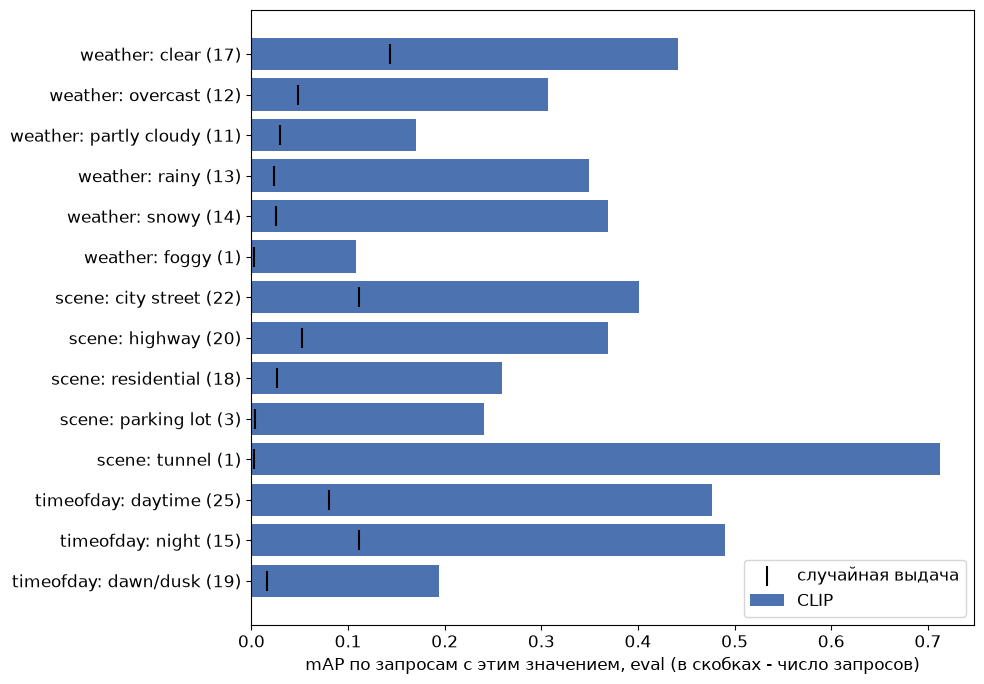

In [8]:
fig, ax = plt.subplots(figsize=(10, 7))
labels = [f"{a}: {v} ({n})" for (a, v), n in zip(by_value.index, by_value.n_queries)]
y = np.arange(len(by_value))[::-1]
ax.barh(y, by_value.ap, color="#4c72b0", label="CLIP")
ax.scatter(by_value.rand_ap, y, color="black", marker="|", s=200, label="случайная выдача")
ax.set_yticks(y, labels)
ax.set_xlabel("mAP по запросам с этим значением, eval (в скобках - число запросов)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(config.RESULTS / "zs_eval_by_value.png", dpi=150)

## 3. Какой атрибут CLIP путает

Для запросов из 2 и 3 атрибутов: доля кадров в топ-50, у которых этот атрибут не совпал с запросом.

In [9]:
miss = pq[pq.n_attrs > 1].groupby("n_attrs")[["miss_weather", "miss_scene", "miss_timeofday"]].mean()
miss.round(3)

,miss_weather,miss_scene,miss_timeofday
n_attrs,,,
2,0.261,0.208,0.125
3,0.285,0.195,0.144


## 4. Удачные и провальные запросы

Сравнивать запросы по сырому AP нельзя: у частых запросов он высокий и у случайной выдачи.
Поэтому сортирую по доле пути от случайной выдачи до идеальной: (AP - AP_rand) / (1 - AP_rand).

In [10]:
pq["ap_norm"] = (pq.ap - pq.rand_ap) / (1 - pq.rand_ap)
cols = ["query_id", "n_relevant", "p@10", "p@50", "ap", "rand_ap", "ap_norm"]
ranked = pq.sort_values("ap_norm", ascending=False)[cols]
display(ranked.head(8).round(3))
display(ranked.tail(8).round(3))

,query_id,n_relevant,p@10,p@50,ap,rand_ap,ap_norm
12,timeofday=night,11965,0.9,0.98,0.990,0.400,0.984
11,timeofday=daytime,15704,1.0,1.00,0.967,0.525,0.931
31,weather=clear|timeofday=night,9892,0.9,0.96,0.928,0.374,0.885
44,scene=city street|timeofday=night,7837,1.0,0.98,0.857,0.263,0.805
10,scene=tunnel,76,0.9,0.88,0.712,0.003,0.711
37,weather=rainy|timeofday=daytime,1010,1.0,0.92,0.717,0.038,0.706
40,weather=snowy|timeofday=daytime,1212,1.0,0.98,0.715,0.046,0.701
46,scene=highway|timeofday=daytime,3842,1.0,0.94,0.731,0.129,0.691


,query_id,n_relevant,p@10,p@50,ap,rand_ap,ap_norm
72,weather=partly cloudy|scene=residential|timeof...,267,0.3,0.22,0.106,0.010,0.097
83,weather=snowy|scene=highway|timeofday=night,104,0.4,0.20,0.100,0.004,0.097
39,weather=rainy|timeofday=dawn/dusk,143,0.4,0.30,0.088,0.006,0.082
69,weather=partly cloudy|scene=city street|timeof...,139,0.3,0.26,0.082,0.006,0.077
75,weather=rainy|scene=city street|timeofday=dawn...,100,0.3,0.22,0.080,0.004,0.077
23,weather=partly cloudy|scene=residential,295,0.2,0.24,0.085,0.012,0.074
67,weather=overcast|scene=residential|timeofday=d...,59,0.3,0.18,0.074,0.003,0.072
17,weather=clear|scene=parking lot,55,0.3,0.14,0.061,0.002,0.059


Топ-6 кадров выдачи для двух лучших и двух худших запросов. Рамка зелёная, если кадр релевантен.
Картинку сохраняю в `artifacts/zs_examples.png` и не показываю здесь: кадры BDD100K в репозиторий не кладу.

In [11]:
frames = data.load_frames("eval")
qs = queries.load_queries()
img = embed.load_image_embeddings(choice["mode"], frames)
model, processor = embed.load_model()
text_emb = evaluate.text_embeddings(model, processor, evaluate.all_texts(qs, choice["template"]))

show = list(ranked.query_id.head(2)) + list(ranked.query_id.tail(2))
sub_q = qs.set_index("query_id").loc[show].reset_index()
scores = evaluate.score_matrix(img, sub_q, choice["template"], choice["scoring"], text_emb)
N_TOP = 6
fig, axes = plt.subplots(len(show), N_TOP, figsize=(N_TOP * 3.2, len(show) * 2.3))
with zipfile.ZipFile(config.IMAGES_ZIP) as z:
    for i, q in enumerate(sub_q.to_dict("records")):
        g = np.flatnonzero(queries.gallery_mask(frames, q, config.GALLERY))
        top = g[np.argsort(-scores[g, i], kind="stable")[:N_TOP]]
        rel = queries.relevant_mask(frames, q)
        for j, idx in enumerate(top):
            r = frames.iloc[idx]
            ax = axes[i, j]
            ax.imshow(data.read_image(z, r.split, r["name"]).resize((320, 180)))
            ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values():
                s.set_color("#2ca02c" if rel[idx] else "#d62728"); s.set_linewidth(4)
            ax.set_title(" / ".join(r[a] for a in config.ATTRS), fontsize=8)
        axes[i, 0].set_ylabel(prompts.query_text(q, "tags"), fontsize=10)
fig.tight_layout()
fig.savefig(config.ARTIFACTS / "zs_examples.png", dpi=110)
plt.close(fig)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]